# Chapitre 6 - Cours 4 : index secondaires et partitionnement

Tant qu'on accède aux données par leur clé, le partitionnement est simple : la clé de
partitionnement désigne la partition, donc le nœud. Mais une vraie application veut aussi
chercher **par valeur** : toutes les voitures rouges, toutes les commandes d'un client,
tous les documents qui contiennent un mot. C'est le rôle des **index secondaires**, et
ils ne se laissent pas découper selon la clé principale. Ce notebook couvre la section
*Partitioning and Secondary Indexes* (sous-sections *Partitioning Secondary Indexes by Document* et *Partitioning Secondary Indexes by Term*).

**Plan.**

1. Le problème : un index secondaire ne suit pas le découpage des données.
2. Les index locaux (partitionnés par document) : écrire sur une partition, lire partout.
3. Le prix du scatter/gather : latence de queue et débit qui ne passe pas à l'échelle.
4. Les index globaux (partitionnés par terme) : lire une partition, écrire sur plusieurs.
5. Comparer et choisir : un modèle de coût et son point de bascule.

In [1]:
import math
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")
SH = "partition"          # vocabulaire de l'édition, pour les figures
SHS = "partitions"
FEM = "e"                              # accord en genre du mot de l'édition

## 1. Le problème : un index secondaire ne suit pas le découpage (section *Partitioning and Secondary Indexes*)

**Le scénario.** Un site d'annonces de voitures d'occasion. Chaque annonce a un
identifiant unique, qui sert de clé de partitionnement : la partition d'une annonce est
déterminée par le haché de son identifiant. Les visiteurs, eux, ne connaissent pas les
identifiants : ils filtrent par **couleur** et par **marque**. Il faut donc des index
secondaires sur ces deux champs : pour chaque valeur (un **terme**, comme
`color:rouge`), la liste des identifiants d'annonces qui la portent. On retrouve la
**liste de postings** de l'index inversé du chapitre 3.

Une entrée d'index secondaire n'identifie pas un enregistrement : elle en désigne
potentiellement des milliers, et rien ne dit qu'ils sont au même endroit. Générons
20 000 annonces (fonction `P.car_listings`, popularités inégales des couleurs et des
marques) réparties sur 8 partitions par haché de l'identifiant, et regardons où se trouvent
les voitures rouges.

In [2]:
N_SHARDS = 8
cars = P.car_listings(20_000, seed=1)
shard_of = np.array([P.doc_shard(c["id"], N_SHARDS) for c in cars])
colors = np.array([c["color"] for c in cars])

par_couleur = pd.crosstab(colors, shard_of).loc[P.COLORS_CARS]
par_couleur.index.name = "couleur"
par_couleur.columns = [f"{SH} {s}" for s in par_couleur.columns]
par_couleur.iloc[:4]

,partition 0,partition 1,partition 2,partition 3,partition 4,partition 5,partition 6,partition 7
couleur,,,,,,,,
rouge,740,801,793,742,773,793,817,802
noir,434,450,436,438,471,428,450,432
blanc,277,296,328,333,341,324,323,320
gris,228,250,267,264,243,252,232,263


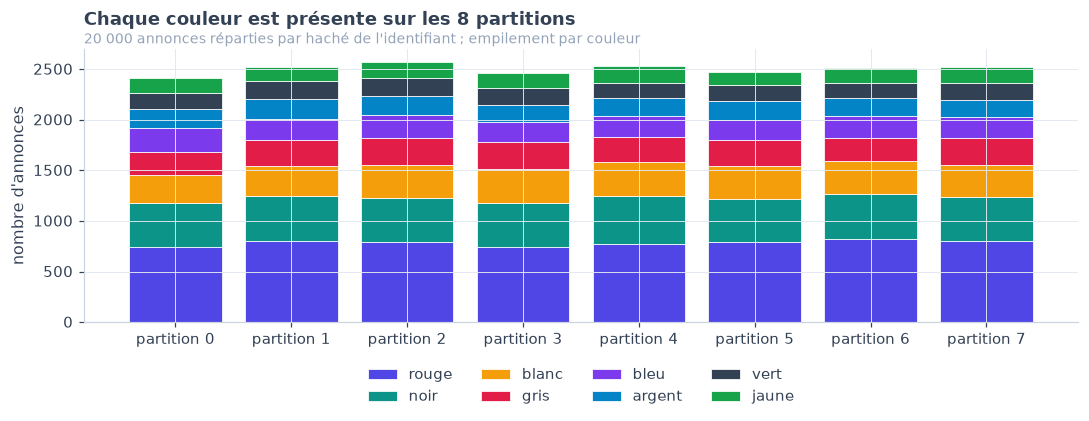

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
bottom = np.zeros(N_SHARDS)
for i, col in enumerate(P.COLORS_CARS):
    vals = par_couleur.loc[col].values
    ax.bar(np.arange(N_SHARDS), vals, bottom=bottom, color=COLORS[i % len(COLORS)], label=col,
           edgecolor="white", lw=0.5)
    bottom += vals
ax.set_xticks(np.arange(N_SHARDS), [f"{SH} {s}" for s in range(N_SHARDS)])
ax.set_ylabel("nombre d'annonces")
ax.set_title(f"Chaque couleur est présente sur les {N_SHARDS} {SHS}")
subtitle(ax, "20 000 annonces réparties par haché de l'identifiant ; empilement par couleur")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

Chaque partition contient environ un huitième de chaque couleur : la répartition par
identifiant est **orthogonale** aux valeurs recherchées. Pour une couleur présente
sur $m$ annonces placées au hasard, la probabilité qu'une partition donnée n'en contienne
aucune vaut $(1 - 1/n)^m$ : avec $m = 1\,205$ voitures jaunes et $n = 8$, c'est
$10^{-70}$. Toute requête « toutes les voitures jaunes » concerne donc **tous** les
partitions. Il n'existe que deux façons de s'en sortir : soit chaque partition indexe ses
propres documents (index **local**), soit l'on construit un index qui couvre toutes les
données et que l'on découpe à son tour, selon le terme (index **global**).

> **À retenir.** Une clé de partitionnement sert les accès par clé ; une valeur
> d'index secondaire désigne des enregistrements dispersés sur toutes les partitions.
> Il faut choisir qui paie : la lecture (index local) ou l'écriture (index global).